In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_3_classification/datasets/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [12]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)
numerical = list(df.dtypes[(df.dtypes == 'float64') | (df.dtypes == 'int64')].index)

df_cat = df[categorical].fillna('NA')
df_num = df[numerical].fillna(0)

df = pd.concat([df_cat, df_num], axis = 1)

In [16]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del(df_train['converted'])
del(df_val['converted'])
del(df_test['converted'])

df_full_train.reset_index(drop = True)
df_train.reset_index(drop = True)
df_val.reset_index(drop = True)
df_test.reset_index(drop = True)

numerical = list(df_train.dtypes[(df_train.dtypes == 'float64') | (df_train.dtypes == 'int64')].index)

In [17]:
from sklearn.metrics import roc_auc_score

for val in numerical:
    score = df_train[val]
    auc = roc_auc_score(y_train, score)

    if(auc < 0.5):
        auc = roc_auc_score(y_train, -score)
        print(f"{val} : {auc:0.3f} {inverted}")
    else:
        print(f"{val} : {auc:0.3f}")

# Ques : 1

annual_income : 0.608
number_of_courses_viewed : 0.723
interaction_count : 0.765
lead_score : 0.788


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical+numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]


from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_val, y_pred)
print(round(auc, 3))

#Ques : 2

0.732


In [45]:
"""
roc_auc_score(y_true, y_score) expects true binary labels (y_val) and predicted probabilities (y_pred).
auc(x, y) computes the area under a curve using raw coordinate points (which expects sorted/increasing or decreasing values, hence the ValueError).
"""

thresholds = np.arange(0.0, 1.0, 0.01) # alternatively np.linspace(0.0, 1.0, 101)
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99])

In [48]:
scores = []

for t in thresholds:
    tp = ((y_pred >= t) & (y_val == 1)).mean()
    tn = ((y_pred < t) & (y_val == 0)).mean()
    fp = ((y_pred >= t) & (y_val == 0)).mean()
    fn = ((y_pred < t) & (y_val == 1)).mean()
    
    # Division by zero warning se bachne ke liye safe check
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append({
        'threshold': t,
        'precision': precision,
        'recall': recall
    })

df_metrics = pd.DataFrame(scores)
df_metrics.tail(5)

,threshold,precision,recall
95,0.95,1.0,0.003413
96,0.96,1.0,0.001706
97,0.97,0.0,0.000000
98,0.98,0.0,0.000000
99,0.99,0.0,0.000000


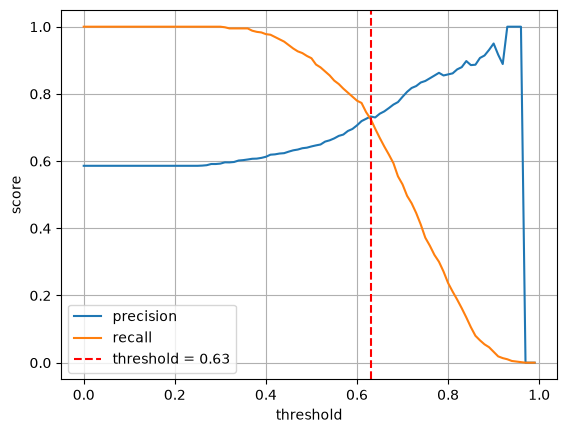

In [56]:
df_metrics['diff'] = abs(df_metrics.precision - df_metrics.recall)

valid = df_metrics[(df_metrics.precision != 0) | (df_metrics.recall != 0)]

best_idx = valid['diff'].idxmin()
best_threshold = valid.loc[best_idx, 'threshold']

plt.plot(df_metrics['threshold'], df_metrics['precision'], label = 'precision')
plt.plot(df_metrics['threshold'], df_metrics['recall'], label='recall')

plt.axvline(x = best_threshold, color='red', linestyle='--', label = f"threshold = {best_threshold:.2f}")

plt.xlabel('threshold')
plt.ylabel('score')

plt.legend()
plt.grid()
plt.show()

# Ques : 3

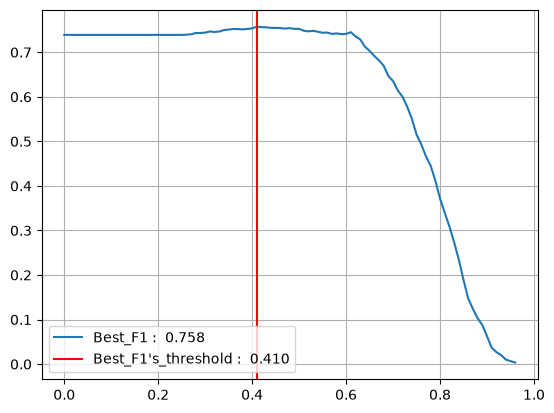

In [71]:
R = df_metrics['recall']
P = df_metrics['precision']
df_metrics['f1_score'] = 2*R*P/(R + P)

best_f1_idx = df_metrics['f1_score'].idxmax()
best_f1 = df_metrics.loc[best_f1_idx, 'f1_score']
best_f1_threshold = df_metrics.loc[best_f1_idx, 'threshold']

plt.plot(df_metrics['threshold'], df_metrics['f1_score'], label = f"Best_F1 : {best_f1: 0.3f}")
plt.axvline(x = best_f1_threshold, color = 'red', label = f"Best_F1's_threshold : {best_f1_threshold: 0.3f}")

plt.grid()
plt.legend()
plt.show()

# Ques : 4

In [78]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 5, shuffle = True, random_state = 1)

kfold_scores = []

C = 1.0

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted
    y_val = df_val.converted

    dv = DictVectorizer(sparse=False)

    train_dict = df_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    model = LogisticRegression(solver = 'liblinear', C = C, max_iter = 1000)
    model.fit(X_train, y_train)

    val_dict = df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dict)
    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    kfold_scores.append(auc)
print("AUC scores:", kfold_scores)
print("Mean AUC:", np.mean(kfold_scores).round(3))
print("Std AUC:", np.std(kfold_scores).round(3))

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Std AUC: 0.007


In [81]:
from tqdm.auto import tqdm

for C in tqdm([0.000001, 0.001, 1]):
    kfold_scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted
        y_val = df_val.converted
    
        dv = DictVectorizer(sparse=False)
    
        train_dict = df_train[categorical + numerical].to_dict(orient='records')
        X_train = dv.fit_transform(train_dict)
        model = LogisticRegression(solver = 'liblinear', C = C, max_iter = 1000)
        model.fit(X_train, y_train)
    
        val_dict = df_val[categorical + numerical].to_dict(orient='records')
        X_val = dv.transform(val_dict)
        y_pred = model.predict_proba(X_val)[:, 1]
    
        auc = roc_auc_score(y_val, y_pred)
    
        kfold_scores.append(auc)

    print(f"C = {C} Mean_AUC = {np.mean(kfold_scores).round(3)} +- {np.std(kfold_scores).round(3)}")

# Ques : 6

  0%|          | 0/3 [00:00<?, ?it/s]

C = 1e-06 Mean_AUC = 0.617 +- 0.019
C = 0.001 Mean_AUC = 0.749 +- 0.01
C = 1 Mean_AUC = 0.732 +- 0.007
